# MSDSF26M008 DS-550 Machine Learning – Assignment 2
Q1 ID3 · Q2 Random Forest · Q3 Decision-Tree Regressor · Q4 Locally Weighted Regression

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time, math
from collections import Counter
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
np.random.seed(42)

# PATH  to data
PATH_12 = "Assignment 2/Data/Q1-2/agaricus-lepiota.data"
PATH_34 = "Assignment 2/Data/Q3-4/"

## Q1 – ID3 decision tree (Mushroom dataset)
### 1.1 Load data and inspect missing values

In [3]:
cols = ["class","cap-shape","cap-surface","cap-color","bruises","odor","gill-attachment","gill-spacing",
        "gill-size","gill-color","stalk-shape","stalk-root","stalk-surface-above-ring","stalk-surface-below-ring",
        "stalk-color-above-ring","stalk-color-below-ring","veil-type","veil-color","ring-number","ring-type",
        "spore-print-color","population","habitat"]
df = pd.read_csv(PATH_12, header=None, names=cols)
print("Shape:", df.shape)
print(df["class"].value_counts())
print("\nMissing values ('?') per column:")
print((df == "?").sum()[lambda s: s > 0])      # only stalk-root has missing values

X = df.drop(columns="class").values.astype(object)
y = df["class"].values
features = list(df.columns[1:])

Shape: (8124, 23)
class
e    4208
p    3916
Name: count, dtype: int64

Missing values ('?') per column:
stalk-root    2480
dtype: int64


### 1.2 Handling missing values
`stalk-root` has 2480 '?' values (~30%). Strategy: **mode imputation computed on the training fold only**
(so no information leaks from the test fold). We also compare with treating '?' as its own category.

In [4]:
def impute_mode(Xtr, Xte, missing="?"):
    Xtr, Xte = Xtr.copy(), Xte.copy()
    for j in range(Xtr.shape[1]):
        col = Xtr[:, j]
        if (col == missing).any():
            vals = col[col != missing]
            mode = Counter(vals).most_common(1)[0][0]
            Xtr[col == missing, j] = mode
            Xte[Xte[:, j] == missing, j] = mode
    return Xtr, Xte

### 1.3 ID3 implementation (entropy + information gain, multiway splits on categorical attributes)

In [5]:
def entropy(y):
    _, c = np.unique(y, return_counts=True)
    p = c / c.sum()
    return -(p * np.log2(p)).sum()

def info_gain(xcol, y):
    H, n, rem = entropy(y), len(y), 0.0
    for v in np.unique(xcol):
        m = xcol == v
        rem += m.sum() / n * entropy(y[m])
    return H - rem

class Node:
    def __init__(self, label, feat=None, children=None):
        self.label, self.feat, self.children = label, feat, children or {}

class ID3:
    def __init__(self, max_features=None, max_depth=None, rng=None):
        self.max_features, self.max_depth = max_features, max_depth
        self.rng = rng or np.random.RandomState(0)
    def fit(self, X, y):
        self.root = self._build(X, y, list(range(X.shape[1])), 0)
        return self
    def _build(self, X, y, avail, depth):
        maj = Counter(y).most_common(1)[0][0]
        if len(set(y)) == 1 or not avail or (self.max_depth is not None and depth >= self.max_depth):
            return Node(maj)
        cand = avail
        if self.max_features is not None and self.max_features < len(avail):   # random-forest feature subset
            cand = list(self.rng.choice(avail, self.max_features, replace=False))
        gains = [info_gain(X[:, j], y) for j in cand]
        best = cand[int(np.argmax(gains))]
        if max(gains) <= 0:
            return Node(maj)
        node = Node(maj, feat=best)
        rest = [a for a in avail if a != best]
        for v in np.unique(X[:, best]):
            m = X[:, best] == v
            node.children[v] = self._build(X[m], y[m], rest, depth + 1)
        return node
    def _pred1(self, x):
        n = self.root
        while n.feat is not None:
            if x[n.feat] not in n.children: break          # unseen value -> majority of this node
            n = n.children[x[n.feat]]
        return n.label
    def predict(self, X):
        return np.array([self._pred1(x) for x in X])
    def depth(self, n=None):
        n = n or self.root
        return 0 if not n.children else 1 + max(self.depth(c) for c in n.children.values())
    def n_nodes(self, n=None):
        n = n or self.root
        return 1 + sum(self.n_nodes(c) for c in n.children.values())

def print_tree(node, names, indent="", maxd=3, d=0):
    if node.feat is None or d >= maxd:
        print(indent + "->", node.label); return
    for v, ch in node.children.items():
        print(f"{indent}[{names[node.feat]} = {v}]")
        print_tree(ch, names, indent + "    ", maxd, d + 1)

### 1.4 5-fold stratified cross-validation

In [6]:
def metrics(yt, yp):
    return dict(Accuracy=accuracy_score(yt, yp),
                Precision=precision_score(yt, yp, pos_label="p"),
                Recall=recall_score(yt, yp, pos_label="p"),
                F1=f1_score(yt, yp, pos_label="p"))

skf = StratifiedKFold(5, shuffle=True, random_state=42)

def cv_model(make_model, impute=True):
    rows, cm_total = [], np.zeros((2, 2), int)
    for k, (tr, te) in enumerate(skf.split(X, y), 1):
        Xtr, Xte = (impute_mode(X[tr], X[te]) if impute else (X[tr], X[te]))
        m = make_model().fit(Xtr, y[tr]); yp = m.predict(Xte)
        r = metrics(y[te], yp); r["Fold"] = k; rows.append(r)
        cm_total += confusion_matrix(y[te], yp, labels=["e", "p"])
    res = pd.DataFrame(rows).set_index("Fold")
    res.loc["Mean"] = res.mean()
    return res, cm_total

t0 = time.time()
res_id3, cm_id3 = cv_model(lambda: ID3())
print("ID3 – mode imputation of '?'"); print(res_id3.round(4)); print("Confusion matrix (rows=true e,p):\n", cm_id3)
res_id3_cat, _ = cv_model(lambda: ID3(), impute=False)    # '?' kept as its own category
print("\nID3 – '?' as a separate category (mean):\n", res_id3_cat.loc["Mean"].round(4))
print("time %.1fs" % (time.time() - t0))

# tree trained on all data (just for display / report)
Xall, _ = impute_mode(X, X)
full_tree = ID3().fit(Xall, y)
print("\nFull tree depth:", full_tree.depth(), " nodes:", full_tree.n_nodes())
print("Root split:", features[full_tree.root.feat]); print_tree(full_tree.root, features, maxd=2)

ID3 – mode imputation of '?'
      Accuracy  Precision  Recall   F1
Fold                                  
1          1.0        1.0     1.0  1.0
2          1.0        1.0     1.0  1.0
3          1.0        1.0     1.0  1.0
4          1.0        1.0     1.0  1.0
5          1.0        1.0     1.0  1.0
Mean       1.0        1.0     1.0  1.0
Confusion matrix (rows=true e,p):
 [[4208    0]
 [   0 3916]]

ID3 – '?' as a separate category (mean):
 Accuracy     1.0
Precision    1.0
Recall       1.0
F1           1.0
Name: Mean, dtype: float64
time 3.6s

Full tree depth: 4  nodes: 29
Root split: odor
[odor = a]
    -> e
[odor = c]
    -> p
[odor = f]
    -> p
[odor = l]
    -> e
[odor = m]
    -> p
[odor = n]
    [spore-print-color = b]
        -> e
    [spore-print-color = h]
        -> e
    [spore-print-color = k]
        -> e
    [spore-print-color = n]
        -> e
    [spore-print-color = o]
        -> e
    [spore-print-color = r]
        -> p
    [spore-print-color = w]
        -> e
   

## Q2 – Random forest (built on our ID3 trees)
Each tree: bootstrap sample of the rows, and at every split only `ceil(sqrt(22)) = 5` randomly chosen
attributes are considered. Prediction = majority vote.

features per split m = 5
Random forest (25 trees)
      Accuracy  Precision  Recall   F1
Fold                                  
1          1.0        1.0     1.0  1.0
2          1.0        1.0     1.0  1.0
3          1.0        1.0     1.0  1.0
4          1.0        1.0     1.0  1.0
5          1.0        1.0     1.0  1.0
Mean       1.0        1.0     1.0  1.0
[[4208    0]
 [   0 3916]]
time 17.6s


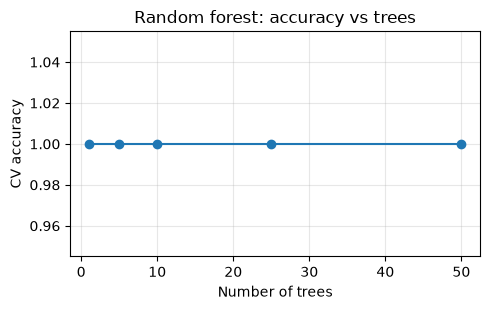

           ID3  Random Forest
Accuracy   1.0            1.0
Precision  1.0            1.0
Recall     1.0            1.0
F1         1.0            1.0


In [7]:
M = math.ceil(math.sqrt(X.shape[1])); print("features per split m =", M)

class RandomForest:
    def __init__(self, n_trees=25, max_features=M, seed=0):
        self.n_trees, self.max_features, self.seed = n_trees, max_features, seed
    def fit(self, X, y):
        rng = np.random.RandomState(self.seed); self.trees = []
        for _ in range(self.n_trees):
            idx = rng.randint(0, len(y), len(y))
            self.trees.append(ID3(max_features=self.max_features, rng=rng).fit(X[idx], y[idx]))
        return self
    def predict(self, X):
        votes = np.array([t.predict(X) for t in self.trees])
        return np.array([Counter(votes[:, i]).most_common(1)[0][0] for i in range(votes.shape[1])])

t0 = time.time()
res_rf, cm_rf = cv_model(lambda: RandomForest(25))
print("Random forest (25 trees)"); print(res_rf.round(4)); print(cm_rf); print("time %.1fs" % (time.time() - t0))

# effect of number of trees (accuracy, 5-fold mean)
ntrees = [1, 5, 10, 25, 50]; accs = []
for nt in ntrees:
    r, _ = cv_model(lambda: RandomForest(nt)); accs.append(r.loc["Mean", "Accuracy"])
plt.figure(figsize=(5, 3.2)); plt.plot(ntrees, accs, "o-"); plt.xlabel("Number of trees"); plt.ylabel("CV accuracy")
plt.title("Random forest: accuracy vs trees"); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig("q2_trees.png", dpi=150); plt.show()

comp = pd.DataFrame({"ID3": res_id3.loc["Mean"], "Random Forest": res_rf.loc["Mean"]}).round(4)
print(comp)

## Q3 – Decision-tree regressor (MSE criterion)

In [8]:
train = pd.read_csv(PATH_34 + "train.csv"); test = pd.read_csv(PATH_34 + "test.csv")
print(train.shape, test.shape, "NaNs:", train.isna().sum().sum(), test.isna().sum().sum())
print(train.describe().round(2))
FEATS = ["bedrooms", "living_in_m2", "real_bathrooms"]
Xtr, ytr = train[FEATS].values, train["price"].values
Xte, yte = test[FEATS].values, test["price"].values

(13603, 4) (6700, 4) NaNs: 0 0
            price  bedrooms  living_in_m2  real_bathrooms
count    13603.00  13603.00      13603.00        13603.00
mean    475286.09      2.24        181.75            1.68
std     207323.21      0.68         67.92            0.63
min      81000.00      1.00         49.24            1.00
25%     315000.00      2.00        130.06            1.00
50%     435000.00      2.00        171.87            2.00
75%     599950.00      3.00        224.83            2.00
max    1155000.00      3.00        391.12            3.00


In [9]:
class RegTree:
    """CART regression tree. Gain = MSE(parent) - weighted MSE(children)."""
    def __init__(self, max_depth=10, min_samples_leaf=5, min_gain=0.0):
        self.max_depth, self.msl, self.min_gain = max_depth, min_samples_leaf, min_gain
    def fit(self, X, y):
        self.root = self._build(X, y, 0); return self
    def _best_split(self, X, y):
        n, best = len(y), (0.0, None, None)
        parent = y.var()
        for j in range(X.shape[1]):
            o = np.argsort(X[:, j], kind="stable"); xs, ys = X[o, j], y[o]
            cs, cs2 = np.cumsum(ys), np.cumsum(ys ** 2)
            nl = np.arange(1, n); nr = n - nl
            ml, mr = cs[:-1] / nl, (cs[-1] - cs[:-1]) / nr
            msel = cs2[:-1] / nl - ml ** 2; mser = (cs2[-1] - cs2[:-1]) / nr - mr ** 2
            gain = parent - (nl * msel + nr * mser) / n
            valid = (xs[1:] != xs[:-1]) & (nl >= self.msl) & (nr >= self.msl)
            if valid.any():
                g = np.where(valid, gain, -np.inf); i = int(np.argmax(g))
                if g[i] > best[0]: best = (g[i], j, (xs[i] + xs[i + 1]) / 2)
        return best
    def _build(self, X, y, d):
        node = dict(value=y.mean(), feat=None)
        if d >= self.max_depth or len(y) < 2 * self.msl or y.var() == 0: return node
        g, j, t = self._best_split(X, y)
        if j is None or g <= self.min_gain: return node
        m = X[:, j] <= t
        node.update(feat=j, thr=t, left=self._build(X[m], y[m], d + 1), right=self._build(X[~m], y[~m], d + 1))
        return node
    def predict(self, X):
        out = np.empty(len(X))
        for i, x in enumerate(X):
            n = self.root
            while n["feat"] is not None: n = n["left"] if x[n["feat"]] <= n["thr"] else n["right"]
            out[i] = n["value"]
        return out

def reg_metrics(yt, yp):
    return dict(MSE=mean_squared_error(yt, yp), RMSE=math.sqrt(mean_squared_error(yt, yp)),
                MAE=mean_absolute_error(yt, yp), R2=r2_score(yt, yp))

### Hyper-parameter selection (validation split of the TRAIN file only – the test file is not touched)

In [10]:
rs = np.random.RandomState(1); perm = rs.permutation(len(ytr)); cut = int(.8 * len(ytr))
a, b = perm[:cut], perm[cut:]
grid = []
for d in [2, 4, 6, 8, 10, 14]:
    for msl in [1, 5, 20, 50]:
        p = RegTree(d, msl).fit(Xtr[a], ytr[a]).predict(Xtr[b])
        grid.append((d, msl, math.sqrt(mean_squared_error(ytr[b], p))))
gdf = pd.DataFrame(grid, columns=["max_depth", "min_samples_leaf", "val_RMSE"]).sort_values("val_RMSE")
print(gdf.head(8).round(1)); best_d, best_msl = int(gdf.iloc[0, 0]), int(gdf.iloc[0, 1]); print("Chosen:", best_d, best_msl)

    max_depth  min_samples_leaf  val_RMSE
7           4                50  165770.0
6           4                20  165832.0
4           4                 1  165832.0
5           4                 5  165832.0
10          6                20  166412.3
11          6                50  166584.0
9           6                 5  166715.9
15          8                50  166756.0
Chosen: 4 50


Decision tree on TEST: {'MSE': 26989121757.225, 'RMSE': 164283.662, 'MAE': 131112.448, 'R2': 0.376}
sklearn check  RMSE: 164289.1  R2: 0.3763


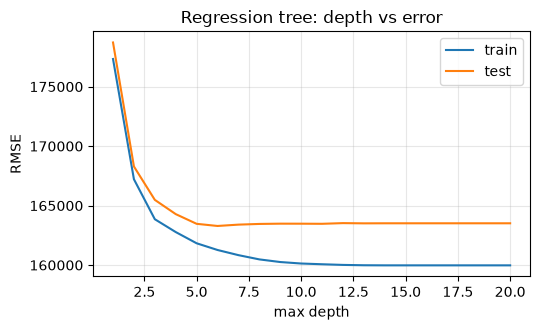

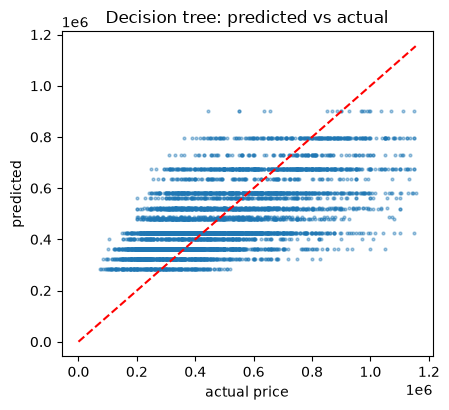

In [11]:
tree = RegTree(best_d, best_msl).fit(Xtr, ytr)
p_tree = tree.predict(Xte); m_tree = reg_metrics(yte, p_tree); print("Decision tree on TEST:", {k: round(v, 3) for k, v in m_tree.items()})

# sanity check against sklearn
from sklearn.tree import DecisionTreeRegressor
sk = DecisionTreeRegressor(max_depth=best_d, min_samples_leaf=best_msl, random_state=0).fit(Xtr, ytr)
print("sklearn check  RMSE:", round(math.sqrt(mean_squared_error(yte, sk.predict(Xte))), 1), " R2:", round(r2_score(yte, sk.predict(Xte)), 4))

# train vs test depth curve
dd = list(range(1, 21)); tr_e, te_e = [], []
for d in dd:
    t_ = RegTree(d, best_msl).fit(Xtr, ytr)
    tr_e.append(math.sqrt(mean_squared_error(ytr, t_.predict(Xtr)))); te_e.append(math.sqrt(mean_squared_error(yte, t_.predict(Xte))))
plt.figure(figsize=(5.5, 3.4)); plt.plot(dd, tr_e, label="train"); plt.plot(dd, te_e, label="test")
plt.xlabel("max depth"); plt.ylabel("RMSE"); plt.legend(); plt.grid(alpha=.3); plt.title("Regression tree: depth vs error")
plt.tight_layout(); plt.savefig("q3_depth.png", dpi=150); plt.show()

plt.figure(figsize=(4.6, 4.2)); plt.scatter(yte, p_tree, s=4, alpha=.4); lim = [0, yte.max()]
plt.plot(lim, lim, "r--"); plt.xlabel("actual price"); plt.ylabel("predicted"); plt.title("Decision tree: predicted vs actual")
plt.tight_layout(); plt.savefig("q3_scatter.png", dpi=150); plt.show()

## Q4 – Locally weighted regression (non-parametric) and comparison
For every query point x: weights  w_i = exp(-||x - x_i||² / (2τ²)),  solve  θ = (XᵀWX + λI)⁻¹ XᵀWy,  predict θᵀx.
Features are standardised (using train mean/std) so that τ means the same for all of them.

In [12]:
mu, sd = Xtr.mean(0), Xtr.std(0)
Ztr, Zte = (Xtr - mu) / sd, (Xte - mu) / sd
ymu, ysd = ytr.mean(), ytr.std()

def lwr_predict(Ztrain, ytrain, Zq, tau, lam=1e-3):
    A = np.hstack([np.ones((len(Ztrain), 1)), Ztrain]); out = np.empty(len(Zq))
    for i, q in enumerate(Zq):
        w = np.exp(-((Ztrain - q) ** 2).sum(1) / (2 * tau ** 2))
        Aw = A * w[:, None]
        theta = np.linalg.solve(A.T @ Aw + lam * np.eye(A.shape[1]), Aw.T @ ytrain)
        out[i] = np.r_[1, q] @ theta
    return out

# tune tau on 600 validation rows held out of train
vi = perm[:600]; ti = perm[600:]
taus = [0.05, 0.1, 0.2, 0.4, 0.8, 1.5]; vr = []
for tau in taus:
    p = lwr_predict(Ztr[ti], ytr[ti], Ztr[vi], tau); vr.append(math.sqrt(mean_squared_error(ytr[vi], p)))
    print(f"tau={tau:<5} val RMSE={vr[-1]:,.0f}")
best_tau = taus[int(np.argmin(vr))]; print("Chosen tau:", best_tau)

tau=0.05  val RMSE=168,328
tau=0.1   val RMSE=167,369
tau=0.2   val RMSE=166,648
tau=0.4   val RMSE=166,552
tau=0.8   val RMSE=166,470
tau=1.5   val RMSE=166,877
Chosen tau: 0.8


LWR time 2s
                                       MSE        RMSE         MAE     R2
Linear regression (baseline)  2.669057e+10  163372.484  130582.332  0.383
Decision tree (Q3)            2.698912e+10  164283.662  131112.448  0.376
LWR (tau=0.8)                 2.643365e+10  162584.282  129965.314  0.389


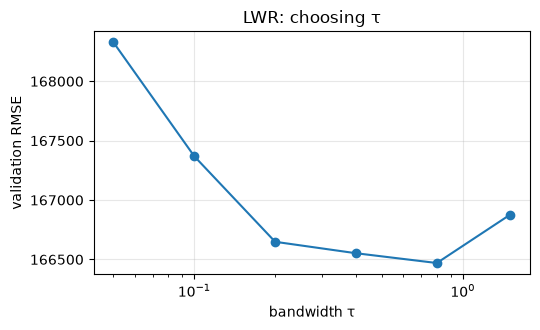

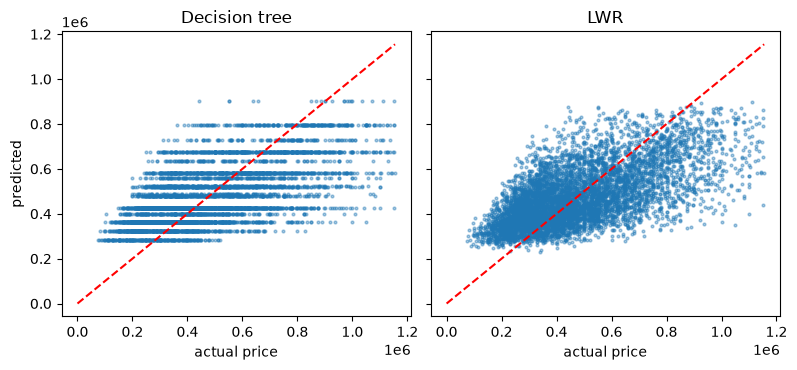

In [13]:
t0 = time.time(); p_lwr = lwr_predict(Ztr, ytr, Zte, best_tau); print("LWR time %.0fs" % (time.time() - t0))
m_lwr = reg_metrics(yte, p_lwr)

from sklearn.linear_model import LinearRegression
p_lin = LinearRegression().fit(Xtr, ytr).predict(Xte); m_lin = reg_metrics(yte, p_lin)

cmp = pd.DataFrame({"Linear regression (baseline)": m_lin, "Decision tree (Q3)": m_tree, f"LWR (tau={best_tau})": m_lwr}).T
print(cmp.round(3))

plt.figure(figsize=(5.5, 3.4)); plt.semilogx(taus, vr, "o-"); plt.xlabel("bandwidth τ"); plt.ylabel("validation RMSE")
plt.grid(alpha=.3); plt.title("LWR: choosing τ"); plt.tight_layout(); plt.savefig("q4_tau.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(8, 3.8), sharey=True)
for a_, p_, t_ in [(ax[0], p_tree, "Decision tree"), (ax[1], p_lwr, "LWR")]:
    a_.scatter(yte, p_, s=4, alpha=.4); a_.plot(lim, lim, "r--"); a_.set_title(t_); a_.set_xlabel("actual price")
ax[0].set_ylabel("predicted"); plt.tight_layout(); plt.savefig("q4_compare.png", dpi=150); plt.show()